# This file helps with combining labels for Brain Metastases MRI Images


In [ ]:
# imports
import numpy as np  # numpy
import pandas as pd # pandas for creating dataframes
import SimpleITK as sitk # SimpleITK
import os


In [18]:
# data paths and patients
data_path = "/Users/rains/rainworkspace/2-IDIALab/Datasets/UCSF_BrainMetastases_v1.3/UCSF_BrainMetastases_TRAIN/"

patientIDs = sorted(os.listdir(data_path)) # patientID list
print(patientIDs[:5]) # preview the patients ids

['100101A', '100102A', '100103A', '100104A', '100104B']


In [33]:
# An example
# load images and see the MRI image details

file_path = "/Users/rains/rainworkspace/2-IDIALab/Datasets/UCSF_BrainMetastases_v1.3/UCSF_BrainMetastases_TRAIN/100101A/100101A_BraTS-seg.nii.gz"

# read the image
image_seg = sitk.ReadImage(file_path) 

# convert the SimpleITK image to a NumPy array
image_seg_array = sitk.GetArrayFromImage(image_seg)
print(image_seg_array.shape)

# find all unique labels in the image
unique_seg_labels = np.unique(image_seg_array)
print(unique_seg_labels)

# Metadata
image_seg_size = image_seg.GetSize()
print("Image Size: ", image_seg_size)

image_seg_spacing = image_seg.GetSpacing() # voxel resolution
print("Spacing (voxel resolution): ", image_seg_spacing)

image_seg_origin = image_seg.GetOrigin()
print("Origin: ", image_seg_origin)

image_seg_direction = image_seg.GetDirection()
print("Direction: ", image_seg_direction)



    


(112, 256, 256)
[0. 1. 2. 3.]
Image Size:  (256, 256, 112)
Spacing (voxel resolution):  (0.8593999743461609, 0.8593999743461609, 1.5)
Origin:  (105.35798645019531, 117.52098846435547, -62.23379898071289)
Direction:  (-1.0, 0.0, 0.0, 0.0, -1.0, 0.0, 0.0, 0.0, 1.0)


Displaying Slice Index: 37 (contains largest tumor section)


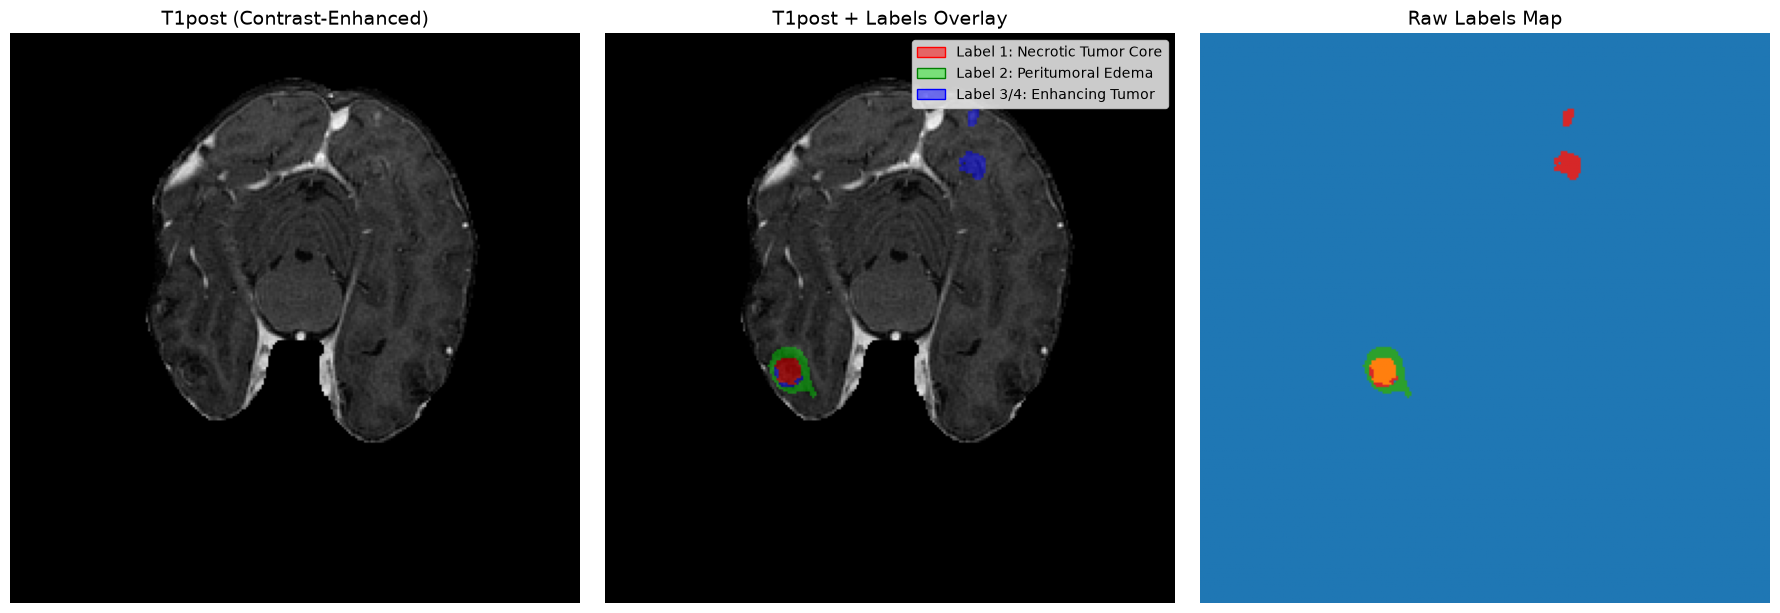

In [20]:
# Visualization
import os
import SimpleITK as sitk
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# 1. Define paths to T1post (contrast-enhanced) and the segmentation labels
patient_dir = "/Users/rains/rainworkspace/2-IDIALab/Datasets/UCSF_BrainMetastases_v1.3/UCSF_BrainMetastases_TRAIN/100101A"
t1post_path = os.path.join(patient_dir, "100101A_T1post.nii.gz")
brats_seg_path = os.path.join(patient_dir, "100101A_BraTS-seg.nii.gz")

# 2. Load the 3D volumes using SimpleITK
t1post_img = sitk.ReadImage(t1post_path)
brats_img = sitk.ReadImage(brats_seg_path)

# Convert to NumPy arrays (shape is Z, Y, X)
t1post_arr = sitk.GetArrayFromImage(t1post_img)
brats_arr = sitk.GetArrayFromImage(brats_img)

# 3. Find the best slice (slice containing the largest tumor volume)
fg_mask = brats_arr > 0
slice_idx = int(np.argmax(fg_mask.sum(axis=(1, 2))))
print(f"Displaying Slice Index: {slice_idx} (contains largest tumor section)")

# Extract 2D slices
t1post_slice = t1post_arr[slice_idx]
labels_slice = brats_arr[slice_idx]

# 4. Construct a custom semi-transparent RGBA overlay for labels
# We use Red for Label 1, Green for Label 2, and Blue for Label 3/4
overlay_rgba = np.zeros(list(labels_slice.shape) + [4])

overlay_rgba[labels_slice == 1] = [1.0, 0.0, 0.0, 0.5]  # Semi-transparent Red
overlay_rgba[labels_slice == 2] = [0.0, 1.0, 0.0, 0.4]  # Semi-transparent Green
overlay_rgba[labels_slice == 3] = [0.0, 0.0, 1.0, 0.5]  # Semi-transparent Blue
overlay_rgba[labels_slice == 4] = [0.0, 0.0, 1.0, 0.5]  # Semi-transparent Blue

# 5. Plot the figures
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Subplot 1: Raw T1post
axes[0].imshow(t1post_slice, cmap="gray")
axes[0].set_title("T1post (Contrast-Enhanced)", fontsize=14)
axes[0].axis("off")

# Subplot 2: T1post + Labels Overlay
axes[1].imshow(t1post_slice, cmap="gray")
axes[1].imshow(overlay_rgba)
axes[1].set_title("T1post + Labels Overlay", fontsize=14)
axes[1].axis("off")

# Custom legend reflecting your colors
legend_elements = [
    Patch(facecolor=[1.0, 0.0, 0.0, 0.5], edgecolor="r", label="Label 1: Necrotic Tumor Core"),
    Patch(facecolor=[0.0, 1.0, 0.0, 0.4], edgecolor="g", label="Label 2: Peritumoral Edema"),
    Patch(facecolor=[0.0, 0.0, 1.0, 0.5], edgecolor="b", label="Label 3/4: Enhancing Tumor")
]
axes[1].legend(handles=legend_elements, loc="upper right")

# Subplot 3: Label Map Only
axes[2].imshow(labels_slice, cmap="tab10", vmin=0, vmax=10)
axes[2].set_title("Raw Labels Map", fontsize=14)
axes[2].axis("off")

plt.tight_layout()
plt.show()


## Notes for the Segmentation Files
What segmentation files are there? What labels does each segmentation files have?
- For [patient_number]_seg.nii, only one label appear (1-red), seems to be "Tumor Core" (enhancing tumor + necrosis)
- For [patient_number]_BraTS-seg.nii, max 3 labels appear.
    - 1-red: necrosis
    - 2-green: edema
    - 3/4-enhancing tumor

Goal:
To combine labels of 
- central necrosis and enhancing tumor into single segmentation file for total tumor volume
- edema in a separate file

In [34]:
# iteration through each patient
# if the patient contains the brats segmentation
#     do labels combining, and save them as [patient_id]_tumorcore.seg.nii and [patient_id]_edema.seg.nii
# if the patient only contains the seg.nii segmentation
#     save it as [patient_id]_tumorcore.seg.nii
# if the patient contains neither
#     show error and catch

num_patients = 1 # int number of patients to process
patient_dataframe = pd.DataFrame() # initialize patient_dataframe, to store status of the patient
patient_record = []

#  method, for loop through number of patients, see labels, no return
def viewPatientFiles(num_patients=None):
    global patient_dataframe, patient_record  # Access the global variables
    patient_record = []                       # Reset records for this run

    for i in range(0, num_patients):
        patientid = patientIDs[i] # string, accessing the ith element of patientID array
        patientDirPath = os.path.join(data_path, patientid)

        # initialize status tracking record
        record = {
            "patient_id": patientid,
            "tumorcore_status": "Not processed",
            "edema_status": "Not processed",
            "status": "Success"
        }

        # safely handle missing patient directory
        if not os.path.exists(patientDirPath):
            record["status"] = "Error: Directory not found"
            patient_record.append(record)
            continue

        patientfiles_names = os.listdir(patientDirPath) # all the files in each patient's directory

        bratsSeg_file = f"{patientid}_BraTS-seg.nii.gz"
        seg_file = f"{patientid}_seg.nii.gz" 

        tumorecore_out_name = f"{patientid}_tumorcore.seg.nii"
        edema_out_name = f"{patientid}_edema.seg.nii"

        # check if it contains the brats segmentation file        
        # if it does contain, then combine the label, save the seg files
        if bratsSeg_file in patientfiles_names:
            bratsSeg_path = os.path.join(patientDirPath, bratsSeg_file)
            bratsSeg_image = sitk.ReadImage(bratsSeg_path)               # Correct path
            bratsSeg_array = sitk.GetArrayFromImage(bratsSeg_image)      # Correct image object

            # combine necrosis (1) and enhancing tumor (3/4) to Tumor Core (Total Tumor Volume)
            tumorcore_array = np.zeros_like(bratsSeg_array, dtype=np.uint8)
            tumorcore_array[np.isin(bratsSeg_array, [1, 3, 4])] = 1

            # save Tumor Core preserving spatial metadata
            tumorecore_img = sitk.GetImageFromArray(tumorcore_array)
            tumorecore_img.CopyInformation(bratsSeg_image)
            sitk.WriteImage(tumorecore_img, os.path.join(patientDirPath, tumorecore_out_name))

            # extract edema (2) as binary mask
            edema_array = np.zeros_like(bratsSeg_array, dtype=np.uint8)
            edema_array[bratsSeg_array == 2] = 1

            # save Edema preserving spatial metadata
            edema_img = sitk.GetImageFromArray(edema_array)
            edema_img.CopyInformation(bratsSeg_image)                    # Correct image object
            sitk.WriteImage(edema_img, os.path.join(patientDirPath, edema_out_name))
            
            record["tumorcore_status"] = "Combined & Saved"
            record["edema_status"] = "Extracted & Saved"
            record["status"] = "Processed (BraTS)"

        # if it does not contain BraTS-seg but contains standard seg, save the seg file directly
        elif seg_file in patientfiles_names:
            seg_img_path = os.path.join(patientDirPath, seg_file)
            seg_image = sitk.ReadImage(seg_img_path)
            
            # Save standard seg as tumorcore directly
            sitk.WriteImage(seg_image, os.path.join(patientDirPath, tumorecore_out_name))
            
            record["tumorcore_status"] = "Saved directly"
            record["edema_status"] = "N/A"
            record["status"] = "Processed (Standard Seg)"

        # if it contains neither
        else:
            record["tumorcore_status"] = "Missing"
            record["edema_status"] = "Missing"
            record["status"] = "Error: No segmentation files found"
            print(f"Warning: Patient {patientid} has no segmentation files.")

        patient_record.append(record)

    # Rebind to the global patient_dataframe
    patient_dataframe = pd.DataFrame(patient_record)

def combineLabels(num_patients=None):
    if num_patients is None:
        num_patients = len(patientIDs)
        viewPatientFiles(num_patients)
        return

    viewPatientFiles(num_patients)

    


In [ ]:
# process a few patients
combineLabels(num_patients=5)

# process all patients
combineLabels()

In [36]:
patient_dataframe

,patient_id,tumorcore_status,edema_status,status
0,100101A,Combined & Saved,Extracted & Saved,Processed (BraTS)
1,100102A,Combined & Saved,Extracted & Saved,Processed (BraTS)
2,100103A,Combined & Saved,Extracted & Saved,Processed (BraTS)
3,100104A,Saved directly,N/A,Processed (Standard Seg)
4,100104B,Saved directly,N/A,Processed (Standard Seg)
